# TweetBiDAF v2 — Attention results and interpretation

This lightweight notebook reports the completed validation experiments and
interprets the saved attention figures. It uses only files in
`a2_v2_colab_artifacts.zip`.

**It does not train a model, load PyTorch checkpoints, use a GPU, or run inference.**
The test set is not accessed. All quantitative claims below are computed from
the saved `runs.csv` and `stage7_summary.json`.


## 0. Load saved results

In [1]:
import csv, io, json, statistics, sys, zipfile
from pathlib import Path
from IPython.display import display, Markdown, Image

# Works locally when the ZIP is next to this notebook and in Colab when it is
# stored in MyDrive/CITS4012_A2_v2.
candidates = [
    Path("a2_v2_colab_artifacts.zip"),
    Path("/content/a2_v2_colab_artifacts.zip"),
    Path("/content/drive/MyDrive/CITS4012_A2_v2/a2_v2_colab_artifacts.zip"),
]
archive = next((p for p in candidates if p.exists()), None)
if archive is None and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    archive = next((p for p in candidates if p.exists()), None)
if archive is None and "google.colab" in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    assert "a2_v2_colab_artifacts.zip" in uploaded
    archive = Path("/content/a2_v2_colab_artifacts.zip")
    archive.write_bytes(uploaded["a2_v2_colab_artifacts.zip"])
assert archive is not None, "Place a2_v2_colab_artifacts.zip beside the notebook or in the configured Drive folder."

zf = zipfile.ZipFile(archive)
names = set(zf.namelist())
required = {"results/runs.csv", "results/stage7_summary.json", "results/figures/self_attn_A3.png"}
assert required <= names, f"Missing required results: {sorted(required - names)}"
runs = list(csv.DictReader(io.StringIO(zf.read("results/runs.csv").decode("utf-8"))))
summary = json.loads(zf.read("results/stage7_summary.json"))
print("Loaded:", archive)
print("Saved runs:", len(runs), "| Saved files:", len(names))
print("REPORT READY — no training or inference will be run")


Loaded: a2_v2_colab_artifacts.zip
Saved runs: 6 | Saved files: 39
REPORT READY — no training or inference will be run


In [2]:
METRICS = ("bleu1", "meteor", "rougeL", "em", "f1")

def model_rows(name):
    return [r for r in runs if r["model"] == name and r["split"] == "val"]

def stats(name, metric):
    xs = [float(r[metric]) for r in model_rows(name)]
    return statistics.mean(xs), statistics.stdev(xs) if len(xs) > 1 else 0.0

main_name, ablated_name = "A5_single_span", "S_A3_no_selfattn"
main, ablated = model_rows(main_name), model_rows(ablated_name)
assert len(main) == len(ablated) == 3, "Expected three validation seeds for both models"

lines = ["| Model | BLEU-1 | METEOR | ROUGE-L | EM | F1 |",
         "|---|---:|---:|---:|---:|---:|"]
for name, label in ((main_name, "TweetBiDAF v2"), (ablated_name, "Without self-attention")):
    cells = [f"{stats(name, m)[0]:.2f} ± {stats(name, m)[1]:.2f}" for m in METRICS]
    lines.append("| " + label + " | " + " | ".join(cells) + " |")
display(Markdown("## 1. Three-seed validation results\n\n" + "\n".join(lines)))

deltas = {m: stats(main_name, m)[0] - stats(ablated_name, m)[0] for m in METRICS}
params_main = int(main[0]["notes"].split("params=")[1].split()[0])
params_a3 = int(ablated[0]["notes"].split("params=")[1].split()[0])
display(Markdown(f"""
### Interpretation

Removing gated self-attention reduces mean **ROUGE-L by {deltas['rougeL']:.2f} points**
and **F1 by {deltas['f1']:.2f} points**. The full model wins on all five reported
metrics. The ablated model has {params_a3:,} parameters, while the full model has
{params_main:,}; self-attention adds {params_main-params_a3:,} parameters.

This controlled result supports the claim that self-attention is useful for this
TweetQA model. It does not prove that attention alone causes every individual
prediction: capacity also changes, and the comparison is on one validation split.
"""))


## 1. Three-seed validation results

| Model | BLEU-1 | METEOR | ROUGE-L | EM | F1 |
|---|---:|---:|---:|---:|---:|
| TweetBiDAF v2 | 38.78 ± 0.17 | 33.22 ± 0.26 | 44.22 ± 0.16 | 27.57 ± 0.99 | 44.34 ± 0.10 |
| Without self-attention | 37.23 ± 0.41 | 31.58 ± 0.50 | 42.41 ± 0.45 | 26.39 ± 0.98 | 42.57 ± 0.47 |


### Interpretation

Removing gated self-attention reduces mean **ROUGE-L by 1.80 points**
and **F1 by 1.77 points**. The full model wins on all five reported
metrics. The ablated model has 3,699,753 parameters, while the full model has
4,094,761; self-attention adds 395,008 parameters.

This controlled result supports the claim that self-attention is useful for this
TweetQA model. It does not prove that attention alone causes every individual
prediction: capacity also changes, and the comparison is on one validation split.


In [3]:
qtype = summary["qtype"]
order = sorted(qtype, key=lambda k: qtype[k]["rougeL"], reverse=True)
lines = ["| Question type | n | ROUGE-L | F1 | EM |",
         "|---|---:|---:|---:|---:|"]
for k in order:
    v = qtype[k]
    lines.append(f"| {k} | {v['n']} | {v['rougeL']:.2f} | {v['f1']:.2f} | {v['em']:.2f} |")
display(Markdown("## 2. Performance by question type\n\n" + "\n".join(lines)))

best, worst = order[0], order[-1]
display(Markdown(f"""
### Interpretation

The model is strongest on **{best}** questions (ROUGE-L {qtype[best]['rougeL']:.2f})
and weakest on **{worst}** questions (ROUGE-L {qtype[worst]['rougeL']:.2f}).
`who` and `where` are also comparatively strong, which fits an extractive span
model: names and locations are often explicit, compact spans. `why` questions
often require explanation or paraphrase rather than copying one span.

Sample size matters. There are {qtype['what']['n']} `what` examples but only
{qtype['why']['n']} `why` examples, so small-category differences have greater
uncertainty and should be described as validation-set observations.
"""))


## 2. Performance by question type

| Question type | n | ROUGE-L | F1 | EM |
|---|---:|---:|---:|---:|
| when | 24 | 53.49 | 53.59 | 20.83 |
| where | 75 | 52.98 | 52.57 | 32.00 |
| who | 290 | 51.92 | 51.88 | 36.55 |
| other | 95 | 45.27 | 45.33 | 27.37 |
| which | 22 | 41.77 | 41.35 | 31.82 |
| what | 462 | 40.52 | 40.67 | 23.59 |
| how | 85 | 35.34 | 35.66 | 15.29 |
| why | 23 | 21.51 | 21.57 | 0.00 |


### Interpretation

The model is strongest on **when** questions (ROUGE-L 53.49)
and weakest on **why** questions (ROUGE-L 21.51).
`who` and `where` are also comparatively strong, which fits an extractive span
model: names and locations are often explicit, compact spans. `why` questions
often require explanation or paraphrase rather than copying one span.

Sample size matters. There are 462 `what` examples but only
23 `why` examples, so small-category differences have greater
uncertainty and should be described as validation-set observations.


In [4]:
tags = summary["auto_tags"]
tag_total = sum(tags.values())
lines = ["| Automatic error category | Count | Share of reviewed sample |",
         "|---|---:|---:|"]
for name, count in sorted(tags.items(), key=lambda x: -x[1]):
    lines.append(f"| {name} | {count} | {100*count/tag_total:.1f}% |")
total_examples = sum(v["n"] for v in summary["qtype"].values())
display(Markdown("## 3. Error analysis\n\n" + "\n".join(lines)))
display(Markdown(f"""
The full-model seed-1 run makes an exact-match error on {summary['n_errors']} of
{total_examples} validation examples. The table describes a deterministic
100-error sample, not all errors.

Boundary or partial-overlap errors are the largest group. This suggests that the
model often locates a relevant region but chooses an imperfect start or end token.
The 23 abstractive cases expose a structural limitation: an extractive model cannot
generate an answer that is not expressible as a suitable tweet span. The 11
body-versus-byline confusions show that author metadata remains difficult even
with username and byline features.
"""))


## 3. Error analysis

| Automatic error category | Count | Share of reviewed sample |
|---|---:|---:|
| boundary / partial overlap | 40 | 40.0% |
| wrong span (no overlap) | 26 | 26.0% |
| abstractive gold (no good span) | 23 | 23.0% |
| byline vs body confusion | 11 | 11.0% |


The full-model seed-1 run makes an exact-match error on 786 of
1076 validation examples. The table describes a deterministic
100-error sample, not all errors.

Boundary or partial-overlap errors are the largest group. This suggests that the
model often locates a relevant region but chooses an imperfect start or end token.
The 23 abstractive cases expose a structural limitation: an extractive model cannot
generate an answer that is not expressible as a suitable tweet span. The 11
body-versus-byline confusions show that author metadata remains difficult even
with username and byline features.


## 4. Attention examples

### Successful `who` example

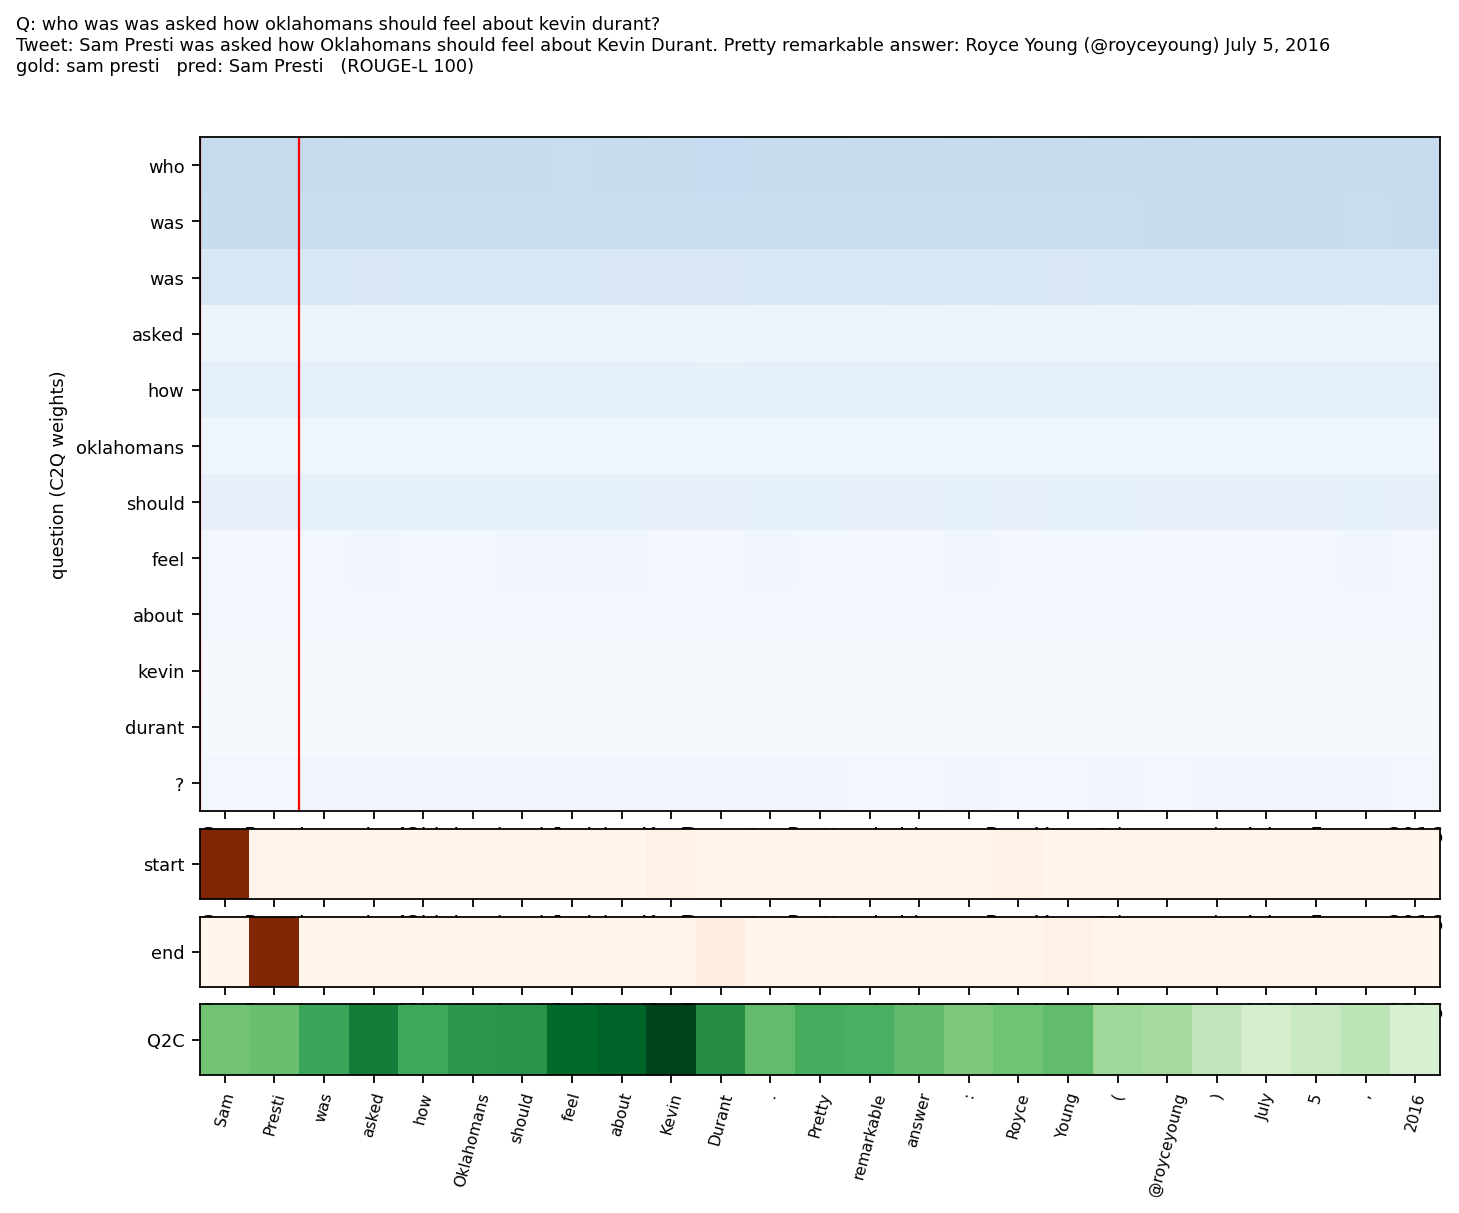


The model predicts **Sam Presti**, exactly matching the reference. The start and
end distributions concentrate on the first two tokens. This is consistent with
the model using the question type and the tweet phrase “was asked,” although the
heatmap alone cannot establish a causal explanation.


### Abstractive-answer failure

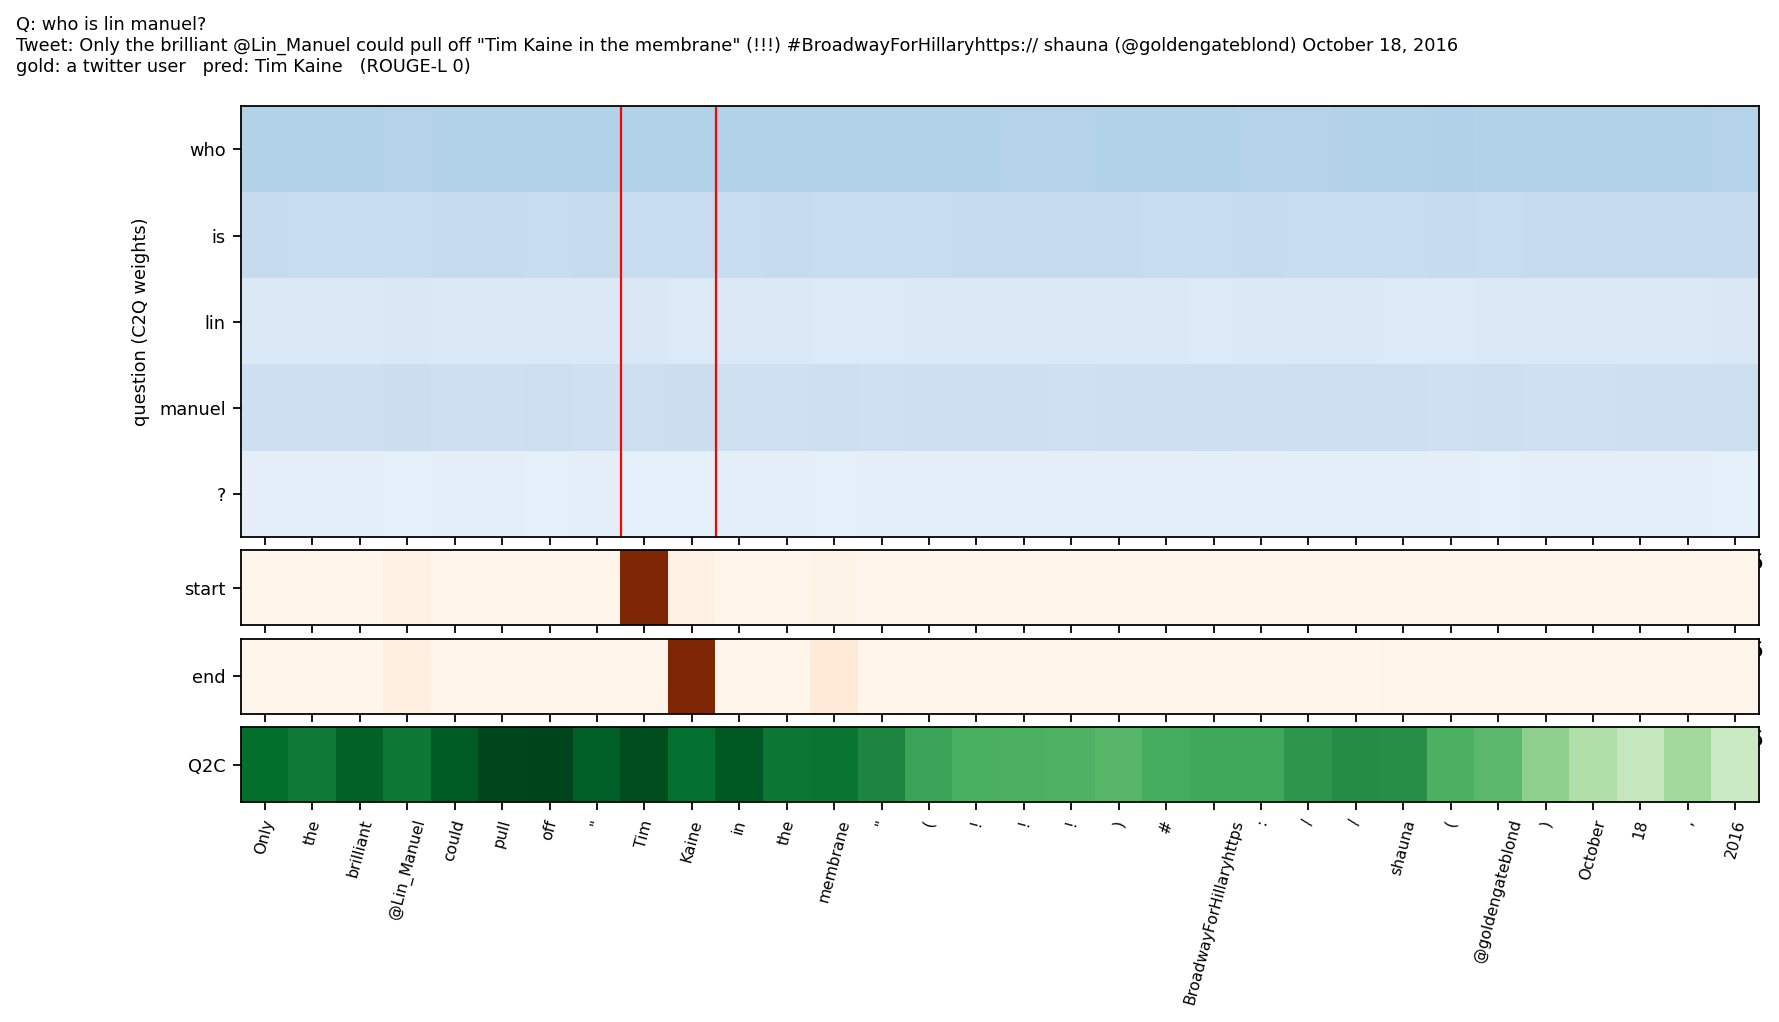


The reference is **a twitter user**, which is a semantic description rather than
the copied name requested by an extractive span selector. The model instead chooses
**Tim Kaine**, a fluent tweet span. This illustrates a task/model mismatch more
than a simple failure to find a nearby keyword.


### Body-versus-byline failure

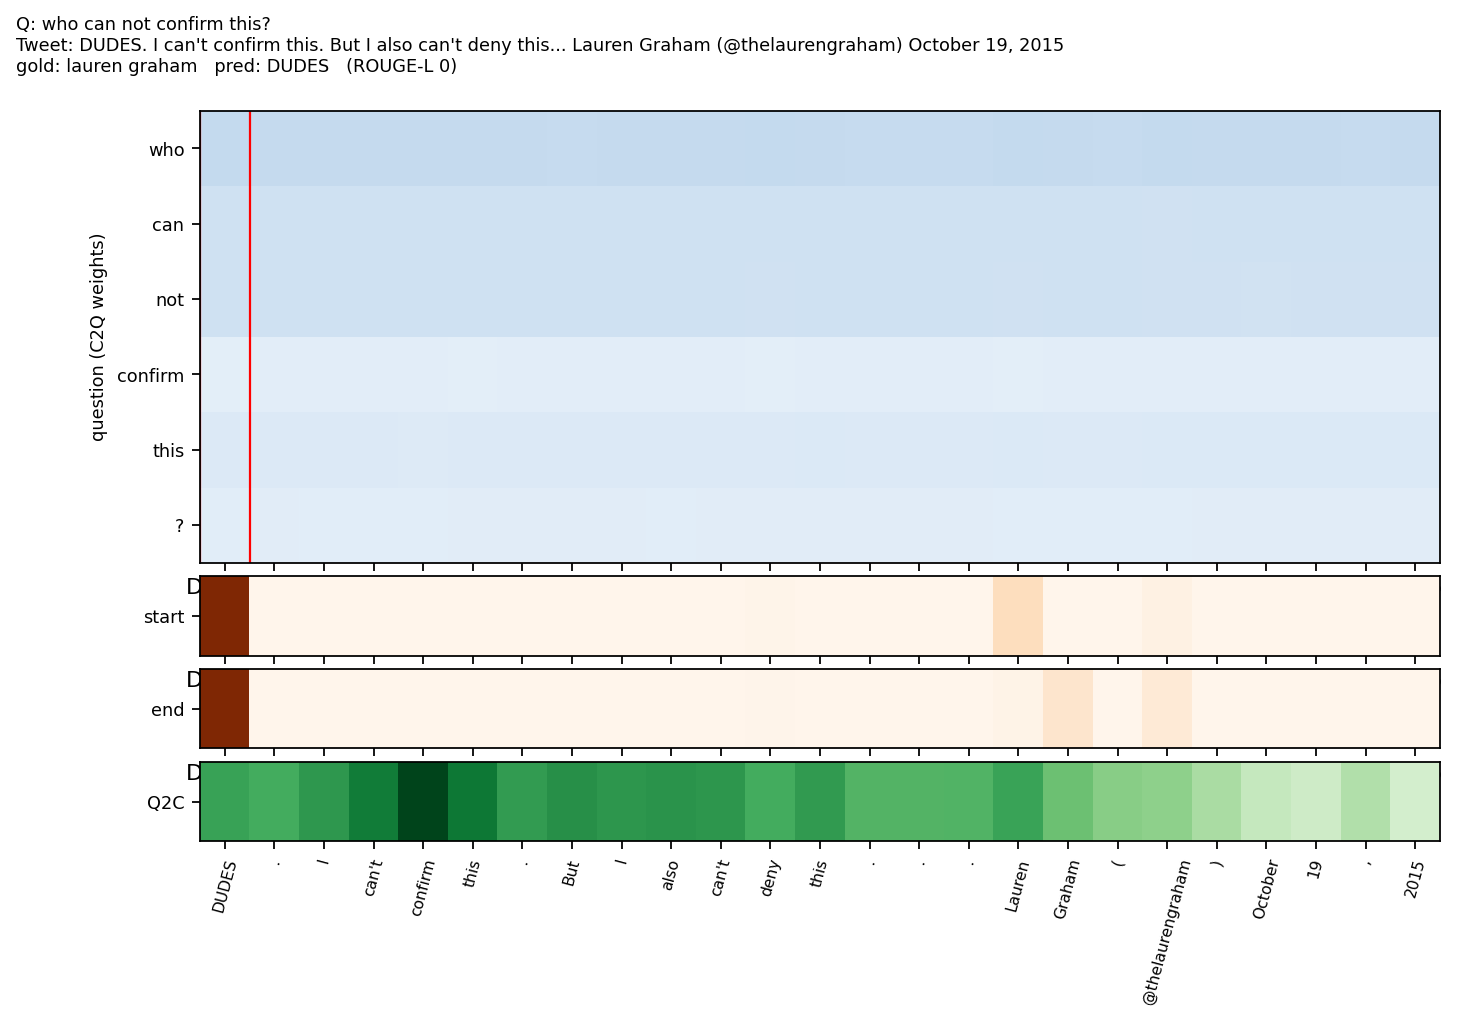


The correct answer, **Lauren Graham**, occurs in the attribution/byline, but the
model predicts **DUDES** from the tweet body. The probability mass shows that the
span head commits strongly to the opening body token, illustrating the remaining
body/byline ambiguity.


### Self-attention comparison

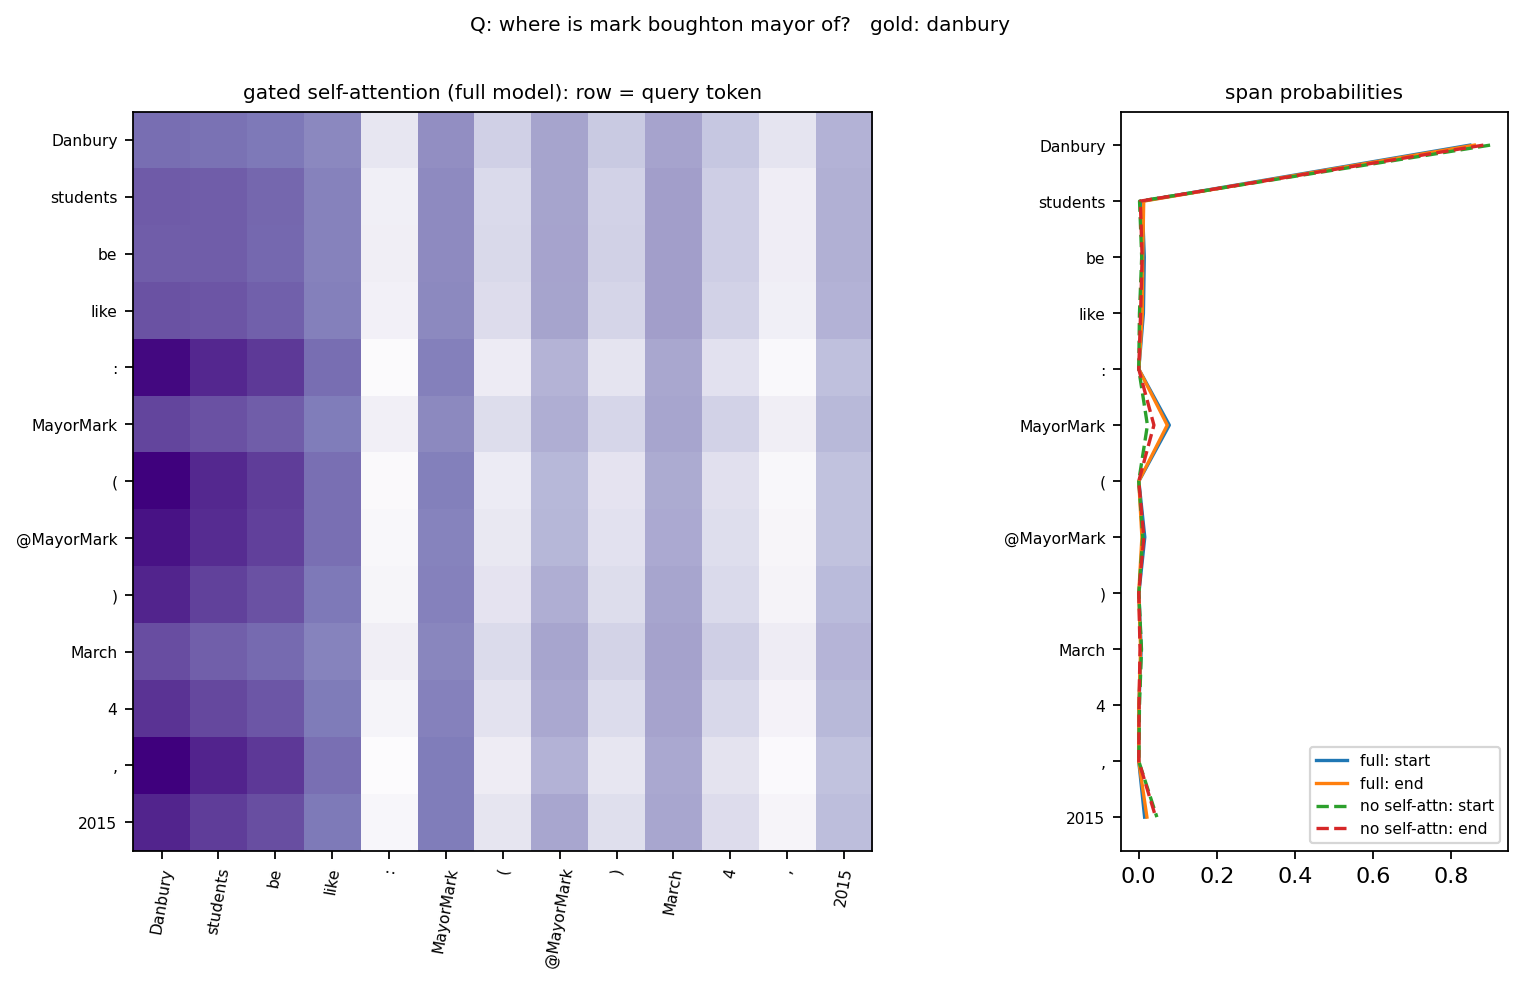


The self-attention map shows token-to-token mixing in the full model, while the
right panel compares span probabilities with and without that block. In this
example both variants strongly favour **Danbury**, so it is evidence of internal
behaviour rather than a dramatic single-example gain. The more reliable evidence
for usefulness is the three-seed ROUGE-L reduction after removing self-attention.


In [5]:
def show_figure(filename, heading, interpretation):
    path = f"results/figures/{filename}"
    if path not in names:
        display(Markdown(f"### {heading}\n\n*Figure missing: `{path}`*"))
        return
    display(Markdown(f"### {heading}"))
    display(Image(data=zf.read(path), format="png", width=1100))
    display(Markdown(interpretation))

display(Markdown("## 4. Attention examples"))
show_figure("attn_success_who.png", "Successful `who` example", """
The model predicts **Sam Presti**, exactly matching the reference. The start and
end distributions concentrate on the first two tokens. This is consistent with
the model using the question type and the tweet phrase “was asked,” although the
heatmap alone cannot establish a causal explanation.
""")
show_figure("attn_fail_abstractive.png", "Abstractive-answer failure", """
The reference is **a twitter user**, which is a semantic description rather than
the copied name requested by an extractive span selector. The model instead chooses
**Tim Kaine**, a fluent tweet span. This illustrates a task/model mismatch more
than a simple failure to find a nearby keyword.
""")
show_figure("attn_fail_username.png", "Body-versus-byline failure", """
The correct answer, **Lauren Graham**, occurs in the attribution/byline, but the
model predicts **DUDES** from the tweet body. The probability mass shows that the
span head commits strongly to the opening body token, illustrating the remaining
body/byline ambiguity.
""")
show_figure("self_attn_A3.png", "Self-attention comparison", """
The self-attention map shows token-to-token mixing in the full model, while the
right panel compares span probabilities with and without that block. In this
example both variants strongly favour **Danbury**, so it is evidence of internal
behaviour rather than a dramatic single-example gain. The more reliable evidence
for usefulness is the three-seed ROUGE-L reduction after removing self-attention.
""")


In [6]:
report = f"""# Attention-analysis report

## Main finding
Across three validation seeds, TweetBiDAF v2 obtains ROUGE-L
{stats(main_name, 'rougeL')[0]:.2f} ± {stats(main_name, 'rougeL')[1]:.2f}.
Removing gated self-attention gives {stats(ablated_name, 'rougeL')[0]:.2f} ±
{stats(ablated_name, 'rougeL')[1]:.2f}, a reduction of {deltas['rougeL']:.2f} points.
The corresponding F1 reduction is {deltas['f1']:.2f} points.

## Interpretation
The controlled ablation supports retaining gated self-attention. Question-type
results suggest that explicit entity and location spans are easier than explanatory
`why` answers. Error sampling indicates that span boundaries, non-extractive gold
answers, and tweet-body versus byline confusion are the main remaining issues.

## Limitation
Attention weights are diagnostic visualisations, not causal explanations. Claims
about component utility should rely primarily on the repeated ablation result.
These are validation results; the locked test set was not accessed.
"""
Path("attention_results_report.md").write_text(report, encoding="utf-8")
display(Markdown("## 5. Report-ready conclusion\n\n" + report))
print("Saved: attention_results_report.md")
zf.close()


## 5. Report-ready conclusion

# Attention-analysis report

## Main finding
Across three validation seeds, TweetBiDAF v2 obtains ROUGE-L
44.22 ± 0.16.
Removing gated self-attention gives 42.41 ±
0.45, a reduction of 1.80 points.
The corresponding F1 reduction is 1.77 points.

## Interpretation
The controlled ablation supports retaining gated self-attention. Question-type
results suggest that explicit entity and location spans are easier than explanatory
`why` answers. Error sampling indicates that span boundaries, non-extractive gold
answers, and tweet-body versus byline confusion are the main remaining issues.

## Limitation
Attention weights are diagnostic visualisations, not causal explanations. Claims
about component utility should rely primarily on the repeated ablation result.
These are validation results; the locked test set was not accessed.


Saved: attention_results_report.md
